In [1]:
import pandas as pd
import numpy as np

# Task 0
Data extraction: get the data from 3 tables & combine it into single `.csv` file.
After that read this file using pandas to create Dataframe.
So it will be all joined data in 1 dataframe. Quick check - should be 74818 rows in it.

In [2]:
import sqlite3
import pandas as pd

conn = sqlite3.connect('../db.sqlite3')

query = """
SELECT * 
FROM restaurant_orderitem
JOIN restaurant_order ON restaurant_orderitem.order_id = restaurant_order.id
JOIN restaurant_product ON restaurant_orderitem.product_id = restaurant_product.id
"""

df = pd.read_sql(query, conn)
conn.close()

df.to_csv('combined_data.csv', index=False)
df = pd.read_csv('combined_data.csv')

print(len(df))

74818


# Task 1
Get Top 10 most popular products in restaurant sold by Quantity.
Count how many times each product was sold and create a pie chart with percentage of popularity (by quantity) for top 10 of them.

Example:

![pie chart](../demo/pie.png)

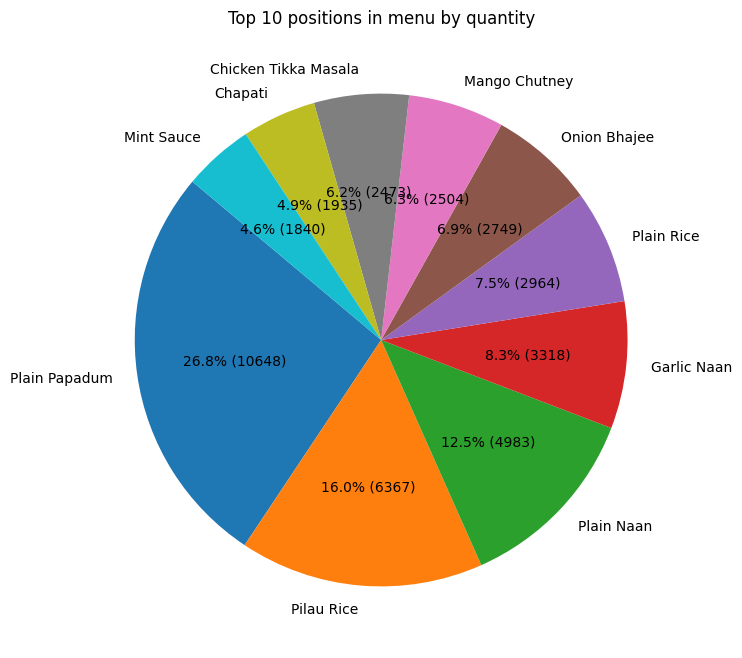

In [16]:
import matplotlib.pyplot as plt

top_10 = df.groupby('name')['quantity'].sum().nlargest(10)

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * sum(values) / 100.0))
        return f'{pct:.1f}% ({val})'
    return my_autopct

plt.figure(figsize=(10, 8))
top_10.plot(kind='pie', autopct=make_autopct(top_10), startangle=140)
plt.title('Top 10 positions in menu by quantity')
plt.ylabel('')
plt.show()

# Task 2
Calculate `Item Price` (Product Price * Quantity) for each Order Item in dataframe.
And Make the same Top 10 pie chart, but this time by `Item Price`. So this chart should describe not the most popular products by quantity, but which products (top 10) make the most money for restaurant. It should be also with percentage.

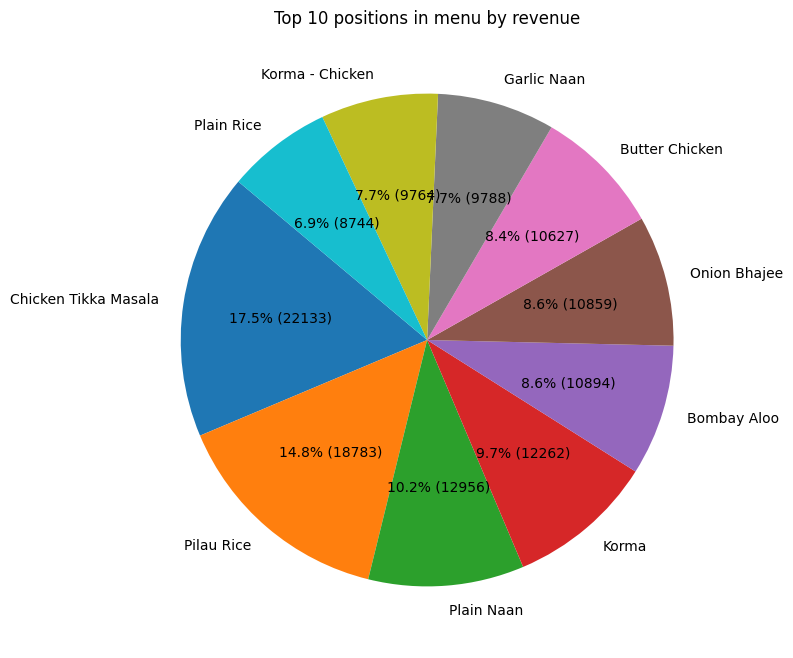

In [15]:
import matplotlib.pyplot as plt

df['item_price'] = df['price'] * df['quantity']

top_10_revenue = df.groupby('name')['item_price'].sum().nlargest(10)

def make_autopct(values):
    def my_autopct(pct):
        val = int(round(pct * sum(values) / 100.0))
        return f'{pct:.1f}% ({val})'
    return my_autopct

plt.figure(figsize=(10, 8))
top_10_revenue.plot(kind='pie', autopct=make_autopct(top_10_revenue), startangle=140)
plt.title('Top 10 positions in menu by revenue')
plt.ylabel('')
plt.show()

# Task 3
Calculate `Order Hour` based on `Order Datetime`, which will tell about the specific our the order was created (from 0 to 23). Using `Order Hour` create a bar chart, which will tell the total restaurant income based on the hour order was created. So on x-axis - it will be values from 0 to 23 (hours), on y-axis - it will be the total sum of order prices, which were sold on that hour.

Example:

![bar chart](../demo/bar.png)

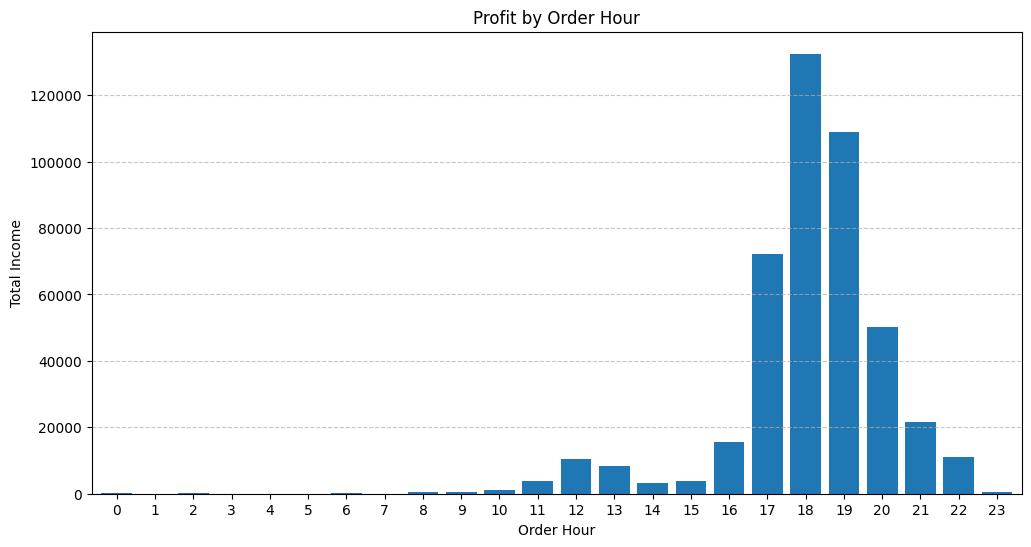

In [14]:
import matplotlib.pyplot as plt


df['datetime'] = pd.to_datetime(df['datetime'])
df['order_hour'] = df['datetime'].dt.hour


hourly_income = df.groupby('order_hour')['item_price'].sum()


hourly_income = hourly_income.reindex(range(24), fill_value=0)


plt.figure(figsize=(12, 6))
hourly_income.plot(kind='bar', color='tab:blue', width=0.8)
plt.title('Profit by Order Hour')
plt.xlabel('Order Hour')
plt.ylabel('Total Income')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Task 4
Make similar bar chart, but right now with `Order Day Of The Week` (from Monday to Sunday), and also analyze total restaurant income by each day of the week.

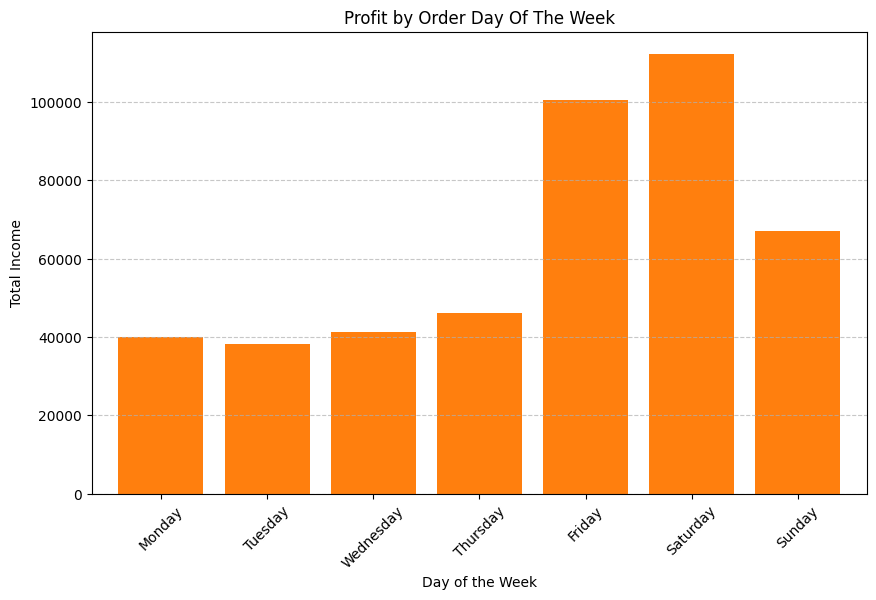

In [13]:
import matplotlib.pyplot as plt


df['order_day'] = df['datetime'].dt.day_name()

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

daily_income = df.groupby('order_day')['item_price'].sum().reindex(days_order)

plt.figure(figsize=(10, 6))
daily_income.plot(kind='bar', color='tab:orange', width=0.8)
plt.title('Profit by Order Day Of The Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Income')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()